In [16]:
%pip install -q selenium webdriver-manager

In [ ]:
# Chrome本体をダウンロード
!wget -q https://dl.google.com/linux/direct/google-chrome-stable_current_amd64.deb -O /tmp/google-chrome.deb

# Chromeと、起動に必要なパッケージをインストール
!apt-get update -qq
!apt-get install -y /tmp/google-chrome.deb

# インストールできたか確認
!google-chrome --version

メールアドレス：mami0328_side@yahoo.co.jp
パスワード：··········
ログインに成功しました！
現在のURL： https://terakoya.sejuku.net/home


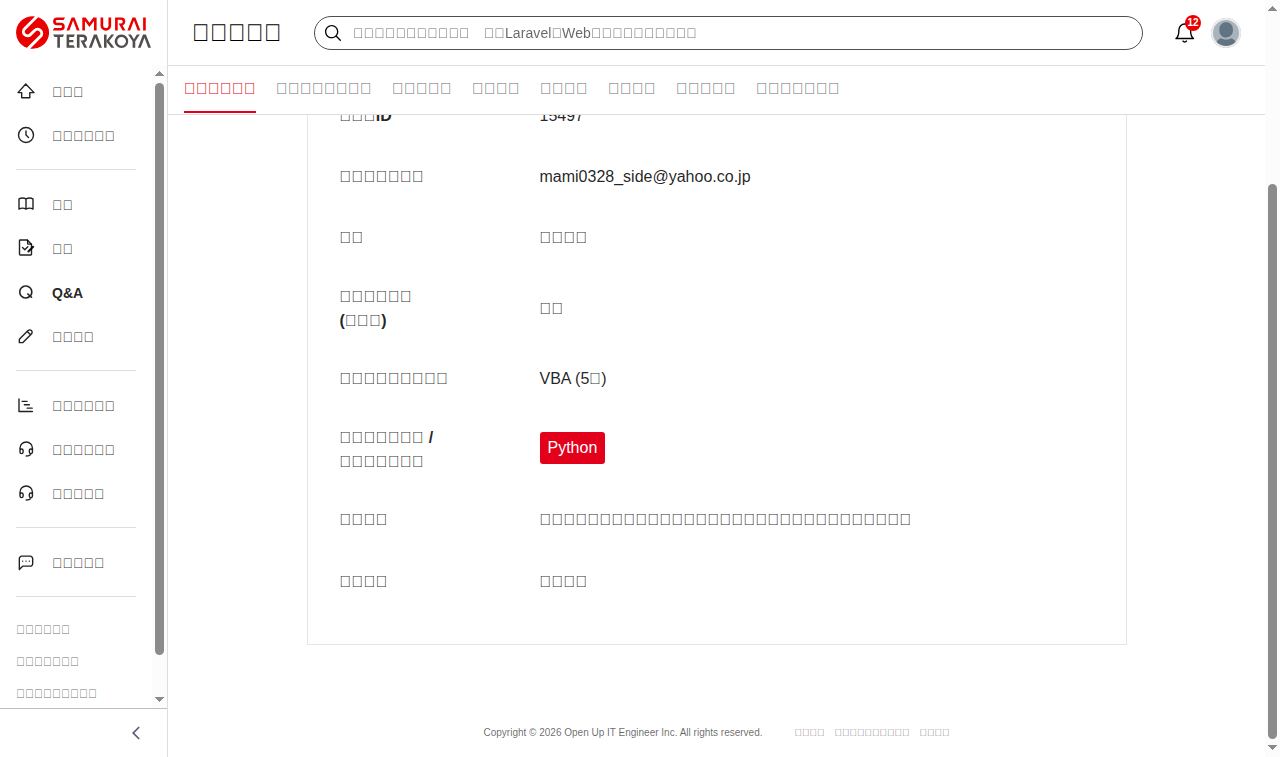

In [20]:


from getpass import getpass

from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.chrome.service import Service
from selenium.webdriver.support.ui import WebDriverWait
from selenium.webdriver.support import expected_conditions as EC
from webdriver_manager.chrome import ChromeDriverManager

from IPython.display import display, Image


# 1. Chromeの設定と起動
chrome_options = webdriver.ChromeOptions()
chrome_options.add_argument('--headless')
chrome_options.add_argument('--no-sandbox')
chrome_options.add_argument('--disable-dev-shm-usage')
chrome_options.add_argument('--window-size=1280,900')

service = Service(ChromeDriverManager().install())

chrome_driver = webdriver.Chrome(
    service=service,
    options=chrome_options
)

wait = WebDriverWait(chrome_driver, 30)
# 2. TERAKOYAを開く
chrome_driver.get('https://terakoya.sejuku.net/register')


# 3. ヘッダーの「ログイン」をクリック
header_login_button = wait.until(
    EC.element_to_be_clickable((
        By.XPATH,
        '//header//*[normalize-space(text())="ログイン"]'
    ))
)
header_login_button.click()


# 4. フォーム内の「ログイン」ボタンを取得
# 入力前は無効なので、存在することを条件に待つ
login_button = wait.until(
    EC.presence_of_element_located((
        By.XPATH,
        '//button[normalize-space(.)="ログイン"]'
    ))
)


# 5. ログインボタンと同じ範囲の入力欄を取得
login_area = login_button.find_element(
    By.XPATH,
    './ancestor::*[.//input[@name="email"] '
    'and .//input[@name="password"]][1]'
)

email_input = login_area.find_element(By.NAME, 'email')
password_input = login_area.find_element(By.NAME, 'password')

wait.until(EC.visibility_of(email_input))
wait.until(EC.visibility_of(password_input))


# 6. ログイン情報を入力
email_address = input('メールアドレス：').strip()
password = getpass('パスワード：')

email_input.clear()
email_input.send_keys(email_address)

password_input.clear()
password_input.send_keys(password)
password_input.send_keys(Keys.TAB)

del password


# 7. ボタンが有効になってからクリック
wait.until(EC.element_to_be_clickable(login_button)).click()


# 8. ホーム画面への移動を待つ
wait.until(
    EC.url_contains('terakoya.sejuku.net/home')
)

print('ログインに成功しました！')
print('現在のURL：', chrome_driver.current_url)


# 9. TERAKOYAプロフィール画面を開く
chrome_driver.get('https://terakoya.sejuku.net/account/profile')


# 10. 「編集」ボタンを押す
edit_button = wait.until(
    EC.element_to_be_clickable((
        By.XPATH,
        '//button[normalize-space(.)="編集"]'
    ))
)
edit_button.click()

# 11. 自己紹介欄を取得
# 現在の画面では、1つ目のtextareaが自己紹介、
# 2つ目が学習目標になっています
introduction_input = wait.until(
    EC.visibility_of_element_located((
        By.CSS_SELECTOR,
        'textarea'
    ))
)

# 12. 既存の自己紹介を消し、課題指定の文章を入力
introduction = (
    'プログラミング学習中です！'
    '今はスクレイピングに挑戦しています！'
)

introduction_input.clear()
introduction_input.send_keys(introduction)

# 13. 「更新する」を押して保存
update_button = wait.until(
    EC.element_to_be_clickable((
        By.XPATH,
        '//button[normalize-space(.)="更新する"]'
    ))
)
update_button.click()

# 14. 編集が終了し、「編集」ボタンに戻るまで待つ
wait.until(
    EC.element_to_be_clickable((
        By.XPATH,
        '//button[normalize-space(.)="編集"]'
    ))
)


# 15. 更新後の画面を表示
chrome_driver.save_screenshot('profile_updated.png')
display(Image(filename='profile_updated.png'))